# My Manufacturing Quality Experiment: Steel Plate Fault Classification
**Samuel O. Esan | Independent machine-learning experiment | Google Colab**

### My research question
Can I use measured properties of existing steel plate faults to predict which fault category each record belongs to?

### Dataset and scope
For this experiment, I used the [UCI Steel Plates Faults dataset](https://archive.ics.uci.edu/dataset/198/steel+plates+faults), which contains **1,941 fault records, 27 input features, and seven fault categories**. Because all observations are associated with existing faults, I am **classifying fault types**, not identifying healthy versus defective plates or deploying an inspection system.

### My approach
I loaded and explored the data, create a stratified train/test split, train Decision Tree and Random Forest models, and compare their results using accuracy, macro-F1, and confusion matrices. I also visualized feature importance and try batch prediction. I used Python, Pandas, NumPy, Scikit-learn, and Matplotlib.

## Step 1 — Preparing my Google Colab
I install `ucimlrepo` so that I can retrieve the public UCI dataset directly into the notebook.

In [1]:
%pip -q install ucimlrepo

## Step 2 — Imported my libraries and load the dataset
I imported the tools I need for analysis, visualization, model training, and evaluation. Then I retrieve the steel plate fault records from UCI and inspect the first few rows.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

steel = fetch_ucirepo(id=198)
X = steel.data.features.copy()
targets = steel.data.targets.copy()
print('Features:', X.shape)
print('Target matrix:', targets.shape)
print('Target columns:', list(targets.columns))
display(X.head())

Features: (1941, 27)
Target matrix: (1941, 7)
Target columns: ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Minimum_of_Luminosity
0,42,50,270900,270944,267,17,44,24220,108,1687,...,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,76
1,645,651,2538079,2538108,108,10,30,11397,123,1687,...,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,84
2,829,835,1553913,1553931,71,8,19,7972,125,1623,...,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,99
3,853,860,369370,369415,176,13,45,18996,126,1353,...,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,99
4,1289,1306,498078,498335,2409,60,260,246930,126,1353,...,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,37


## Step 3 — I inspected the labels and check data quality
I verified that each record has exactly one fault category. UCI provides seven one-hot encoded target columns, so I convert them into one class label per observation with `idxmax`.

I also check for missing values and nonnumeric inputs. I **do not** include the target columns among my input features, because that would leak the answers to the models.

In [3]:
assert (targets.sum(axis=1) == 1).all(), 'Unexpected target format: check UCI dataset.'
y = targets.idxmax(axis=1)
print('Rows:', len(X), '| Input measurements:', X.shape[1])
print('Missing cells:', int(X.isna().sum().sum()))
print('Fault classes:', y.value_counts())
print('Non-numeric input columns:', X.select_dtypes(exclude='number').columns.tolist())

Rows: 1941 | Input measurements: 27
Missing cells: 0
Fault classes: Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64
Non-numeric input columns: []


## Step 4 — Visualize the distribution of fault categories
I counted how many observations belong to each fault category and create a bar chart. This helps me see whether the categories are imbalanced, which is why I will evaluate macro-F1 in addition to accuracy.

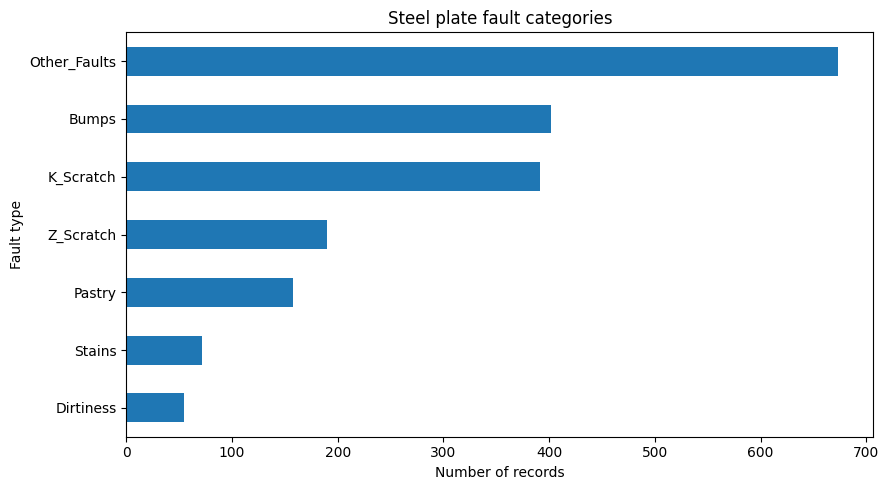

In [4]:
counts = y.value_counts().sort_values()
ax = counts.plot(kind='barh', figsize=(9,5))
ax.set(title='Steel plate fault categories', xlabel='Number of records', ylabel='Fault type')
plt.tight_layout()
plt.savefig('fault_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

## Step 5 — I create a stratified training and testing split
I reserved **20%** of the records for testing and use **80%** to train my models. I choose `stratify=y` to maintain approximately the same category proportions in each subset. I use `random_state=42` so the split is reproducible.

I did not inspect the test labels to tune the models during this initial experiment.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training records:', len(X_train), '| Test records:', len(X_test))

Training records: 1552 | Test records: 389


## Step 6 — I train the Decision Tree and Random Forest
Started with a Decision Tree as a straightforward baseline. I then train a Random Forest, which combines many decision trees. I compared the two to see whether the ensemble performs better on this particular dataset.

For this initial comparison, I used a maximum depth of eight for the Decision Tree and 200 trees for the Random Forest. These are my starting settings, not hyperparameters selected by a tuning experiment.

In [6]:
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print('Trained:', name)

Trained: Decision Tree
Trained: Random Forest


## Step 7 — Measure model performance on held-out data
I predicted the fault categories for records the models did not see during training.

- **Accuracy** tells me what fraction of test predictions are correct.
- **Macro-F1** averages the F1-score of each fault category equally and helps reveal uneven class performance.

I also recorded the results produced by my run instead of inventing or estimating performance.

In [7]:
results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro F1': f1_score(y_test, predictions, average='macro', zero_division=0)
    })
    print(f'\n=== {name} ===')
    print(classification_report(y_test, predictions, zero_division=0))
results_df = pd.DataFrame(results).set_index('Model')
display(results_df.round(3))
results_df.to_csv('model_comparison.csv')


=== Decision Tree ===
              precision    recall  f1-score   support

       Bumps       0.66      0.59      0.62        81
   Dirtiness       1.00      0.82      0.90        11
   K_Scratch       0.98      0.81      0.89        78
Other_Faults       0.64      0.71      0.68       135
      Pastry       0.43      0.62      0.51        32
      Stains       0.92      0.79      0.85        14
   Z_Scratch       0.94      0.89      0.92        38

    accuracy                           0.72       389
   macro avg       0.80      0.75      0.77       389
weighted avg       0.75      0.72      0.73       389


=== Random Forest ===
              precision    recall  f1-score   support

       Bumps       0.74      0.67      0.70        81
   Dirtiness       0.89      0.73      0.80        11
   K_Scratch       0.97      0.94      0.95        78
Other_Faults       0.71      0.84      0.77       135
      Pastry       0.68      0.53      0.60        32
      Stains       0.92      0.8

,Accuracy,Macro F1
Model,,
Decision Tree,0.722,0.766
Random Forest,0.797,0.803


## Step 8 — Compare the scores visually
I created a bar chart comparing Decision Tree and Random Forest accuracy and macro-F1. This helps me see which model performs better on my held-out test set.

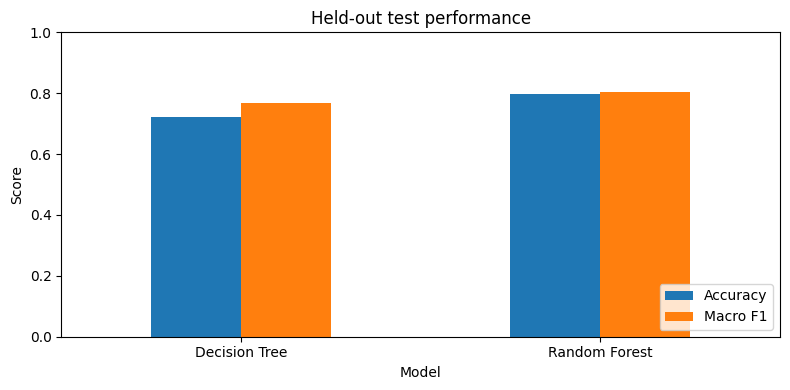

In [8]:
ax = results_df.plot(kind='bar', figsize=(8,4), rot=0)
ax.set(title='Held-out test performance', ylabel='Score', ylim=(0,1))
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## Step 9 — Inspect classification mistakes
I plot a confusion matrix for each model. I read each **row** as the actual fault category and each **column** as the predicted category. Values on the diagonal are correct predictions; off-diagonal values show mistakes.

I focused not only on the overall winning model but also on which fault category it struggles to identify.

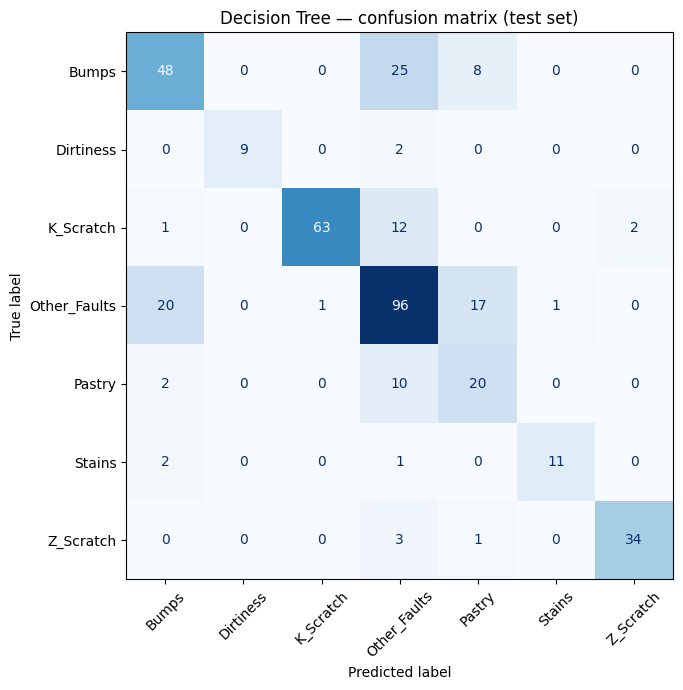

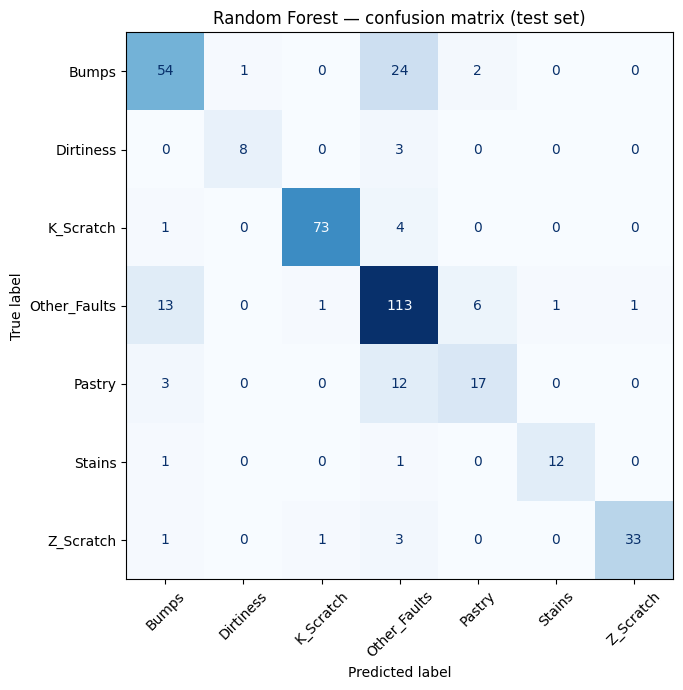

In [9]:
for name, model in models.items():
    fig, ax = plt.subplots(figsize=(9,7))
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, xticks_rotation=45,
        cmap='Blues', colorbar=False
    )
    ax.set_title(name + ' — confusion matrix (test set)')
    plt.tight_layout()
    plt.savefig(name.lower().replace(' ', '_')+'_confusion_matrix.png',
                dpi=160, bbox_inches='tight')
    plt.show()

## Step 9A — calculate recall by fault category
To support my answer about classification errors, I calculate recall separately for each fault category using the winning model. This gives me the exact value to compare with the confusion matrix instead of estimating it visually.

In [10]:
from sklearn.metrics import recall_score, confusion_matrix

# I select the model with the highest macro-F1 on this held-out comparison.
best_name = results_df['Macro F1'].idxmax()
best_model = models[best_name]
best_predictions = best_model.predict(X_test)
class_labels = sorted(y_test.unique())
recalls = recall_score(y_test, best_predictions, labels=class_labels, average=None, zero_division=0)
recall_table = pd.DataFrame({'Fault category': class_labels, 'Recall': recalls})
print('Best model in this run:', best_name)
display(recall_table.sort_values('Recall').reset_index(drop=True))

# I check the number of correct and incorrect predictions for each class.
confusion = confusion_matrix(y_test, best_predictions, labels=class_labels)
print('Correct predictions:', int(np.trace(confusion)), 'of', int(confusion.sum()))

Best model in this run: Random Forest


,Fault category,Recall
0,Pastry,0.531250
1,Bumps,0.666667
2,Dirtiness,0.727273
3,Other_Faults,0.837037
4,Stains,0.857143
5,Z_Scratch,0.868421
6,K_Scratch,0.935897


Correct predictions: 310 of 389


## Step 10 — I examine feature importance
I plotted the ten highest impurity-based feature importance values from my Random Forest. This helps me identify which measured inputs the model uses most for its splits.

I then treat these scores as **model-specific importance**, not proof that any measurement causes a fault.

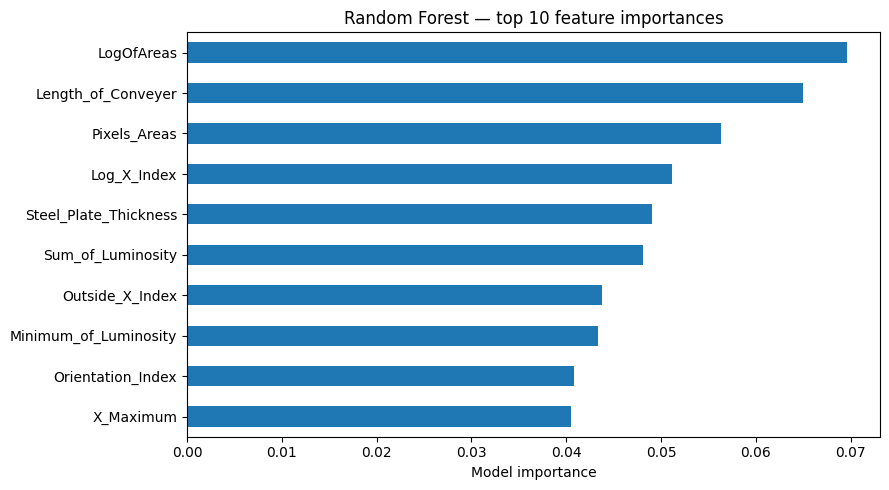

In [11]:
importance = pd.Series(models['Random Forest'].feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=False).head(10).sort_values()
ax = top10.plot(kind='barh', figsize=(9,5))
ax.set(title='Random Forest — top 10 feature importances', xlabel='Model importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=160, bbox_inches='tight')
plt.show()

## Step 11 —Ttest batch prediction
I selected five records from the held-out test data and use my Random Forest to predict their fault categories together. I then compared the predictions with the known labels.

I use **batch prediction** here to mean predicting multiple records at once; it is different from submitting a batch job on a computing cluster.

In [12]:
samples = X_test.head(5)
batch_predictions = models['Random Forest'].predict(samples)
preview = pd.DataFrame({
    'Predicted fault': batch_predictions,
    'Actual fault': y_test.loc[samples.index].to_numpy()
}, index=samples.index)
display(preview)

,Predicted fault,Actual fault
1710,Other_Faults,Other_Faults
863,Other_Faults,Dirtiness
1174,Bumps,Bumps
1815,Other_Faults,Other_Faults
370,K_Scratch,K_Scratch


## Step 12 — Summary

### 1. Data: How many fault records, input features, and categories did I analyze?
I analyzed 1,941 steel plate fault records with 27 input features and seven fault categories.

### 2. Methods: Why did I use a stratified split, and why did I compare these models?
I used a stratified train/test split so that each fault category was represented in approximately the same proportion across both sets. I compared a single Decision Tree with a Random Forest to examine whether an ensemble of trees would improve classification performance.

### 3. Results: Which model had the higher macro-F1?
In the Colab run I recorded, my **Random Forest** scored **0.8034 macro-F1** and **79.69% accuracy**, compared with **0.7664 macro-F1** and **72.24% accuracy** for the Decision Tree. The Random Forest correctly classified **310 of 389** test observations, while the Decision Tree correctly classified **281 of 389**.

### 4. Errors: Which class did my best model struggle with?
In the confusion matrix from that run, my Random Forest performed worst on **Pastry** when measured by recall. It correctly classified **17 of 32 Pastry records (53.13% recall)**. Of the others, **12** were predicted as `Other_Faults` and **3** as `Bumps`.

### 5. Limitations: What can I not conclude?
All rows describe **existing steel plate faults**. I cannot use these results to claim that my model detects whether an otherwise healthy plate is defective. I also cannot assume this dataset represents another factory, machine, material, or production environment. My results come from one held-out split and do not establish deployment readiness.

### 6. Next experiment: What would improve my confidence?
I would use **stratified cross-validation** to evaluate variability across splits, **hyperparameter tuning** to explore model settings without optimizing against the final test set, and **additional industrial datasets** to check generalizability. I would also investigate ways to improve recall for the Pastry fault category.

### My takeaway
I found that Random Forest performed better overall than Decision Tree in my initial experiment, but I also identified weaker performance for one category. This taught me why model evaluation must look beyond accuracy alone.

**Portfolio integrity:** This is not a deployed system, an industrial field validation, or a healthy-versus-defective detector.